In [80]:
import pandas as pd
from glob import glob
import re
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
import json
import torch
import numpy as np
from bbox_annotation import Annotation, annotation_from_json
from sklearn.model_selection import train_test_split

from tool import crop_rgb

In [81]:
np.random.seed(0)

In [82]:
Image.MAX_IMAGE_PIXELS = None

In [83]:
image_pattern = re.compile(r"(.*)\.([^\.]*)")

In [84]:
data = []

In [85]:
from thing import thing

for i in glob("dataset/images/*"):
    name = Path(i).stem

    annotation_file = Path("dataset/bbox_annotation").joinpath(f"{name}.json")

    try:
        with open(annotation_file, "r") as annotation_file:
            annotation: Annotation = annotation_from_json(json.load(annotation_file))
    except FileNotFoundError as e:
        print(f"{annotation_file} not found, skipping")
        continue

    image = Image.open(i)

    if image.width != annotation["width"] or image.height != annotation["height"]:
        print(f"{annotation_file} has w: {annotation["width"]} h: {annotation["height"]}, but image has dimension w: {annotation["width"]} h: {annotation["height"]}, skipping")
        continue

    data.append({
        "Name": name,
        "Image": i,
        "Image Width": image.width,
        "Image Height": image.height,
        "Depth Column": annotation["bounding_boxs"]["depth_column"],
        "Interpreted Lithology Column": annotation["bounding_boxs"]["interpreted_lithology_column"],
        "Lithology Legend": annotation["bounding_boxs"]["lithology_legend"],
    })
    data.append(thing(Path(i), annotation))

data

dataset/bbox_annotation/60811406050000_608114060500_g31765 001 st00 bp00__master log_5640-28740_5 in_md(1).json not found, skipping


[{'Name': '60811405800000_608114058000_g16786_001_00_00_md5_mud_show_2',
  'Image': 'dataset/images/60811405800000_608114058000_g16786_001_00_00_md5_mud_show_2.tif',
  'Image Width': 1534,
  'Image Height': 2600,
  'Depth Column': Box(x1=275, y1=1576, x2=355, y2=2575),
  'Interpreted Lithology Column': Box(x1=1165, y1=1576, x2=1228, y2=2575),
  'Lithology Legend': Box(x1=2, y1=599, x2=1532, y2=1002)},
 {'name': '60811405800000_608114058000_g16786_001_00_00_md5_mud_show_2',
  'image': PosixPath('dataset/images/60811405800000_608114058000_g16786_001_00_00_md5_mud_show_2.tif'),
  'width': 1534,
  'height': 2600,
  'depth_column': Box(x1=275, y1=1576, x2=355, y2=2575),
  'interpreted_lithology_column': Box(x1=1165, y1=1576, x2=1228, y2=2575),
  'lithology_legend': Box(x1=2, y1=599, x2=1532, y2=1002)},
 {'Name': '60807402860000_gb506#2_md_mudlog',
  'Image': 'dataset/images/60807402860000_gb506#2_md_mudlog.tif',
  'Image Width': 1536,
  'Image Height': 9623,
  'Depth Column': Box(x1=236, y1

In [86]:
data_df = pd.DataFrame(data)
data_df

,Name,Image,Image Width,Image Height,Depth Column,Interpreted Lithology Column,Lithology Legend,name,image,width,height,depth_column,interpreted_lithology_column,lithology_legend
0,60811405800000_608114058000_g16786_001_00_00_m...,dataset/images/60811405800000_608114058000_g16...,1534.0,2600.0,"(275, 1576, 355, 2575)","(1165, 1576, 1228, 2575)","(2, 599, 1532, 1002)",NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,60811405800000_608114058000_g16786_001_00_00_m...,dataset/images/60811405800000_608114058000_g16...,1534.0,2600.0,"(275, 1576, 355, 2575)","(1165, 1576, 1228, 2575)","(2, 599, 1532, 1002)"
2,60807402860000_gb506#2_md_mudlog,dataset/images/60807402860000_gb506#2_md_mudlo...,1536.0,9623.0,"(236, 1206, 316, 9623)","(953, 1206, 1000, 9623)","(12, 596, 1525, 1003)",NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,60807402860000_gb506#2_md_mudlog,dataset/images/60807402860000_gb506#2_md_mudlo...,1536.0,9623.0,"(236, 1206, 316, 9623)","(953, 1206, 1000, 9623)","(12, 596, 1525, 1003)"
4,0000000009_d-582_0000020435-0001_log07_chromat...,dataset/images/0000000009_d-582_0000020435-000...,4864.0,12031.0,"(1278, 4387, 1369, 11175)","(1357, 4387, 1606, 11175)","(1938, 1513, 3030, 2655)",NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
97,NaN,NaN,NaN,NaN,NaN,NaN,NaN,MC765_P011_ST00BP00_5inchTVD_Depth_MudLog_3686...,dataset/images/MC765_P011_ST00BP00_5inchTVD_De...,1700.0,134200.0,"(377, 1623, 448, 132811)","(1134, 1623, 1171, 132811)","(79, 904, 1621, 1327)"
98,Callaway 3-33 mudlog to TD.PDF,dataset/images/Callaway 3-33 mudlog to TD.PDF.tif,1275.0,56100.0,"(555, 5096, 615, 56024)","(250, 5096, 310, 56024)","(26, 2081, 1248, 2381)",NaN,NaN,NaN,NaN,NaN,NaN,NaN
99,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Callaway 3-33 mudlog to TD.PDF,dataset/images/Callaway 3-33 mudlog to TD.PDF.tif,1275.0,56100.0,"(555, 5096, 615, 56024)","(250, 5096, 310, 56024)","(26, 2081, 1248, 2381)"
100,Shell_AC0336_OCS-G-36102_001_ST00BP01_5inchMD_...,dataset/images/Shell_AC0336_OCS-G-36102_001_ST...,1275.0,143550.0,"(340, 1129, 400, 142323)","(400, 1129, 450, 142323)","(30, 668, 1208, 832)",NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [87]:
import pickle
with open("dataset.pickle", "wb") as f:
    f.write(pickle.dumps(data_df))

In [88]:
%store data_df

Stored 'data_df' (DataFrame)


In [89]:
training_dataset, rest = train_test_split(data_df, test_size=0.3, random_state=0)
validation_dataset, testing_dataset = train_test_split(rest, test_size=0.5, random_state=0)

display(training_dataset)
display(validation_dataset)
display(testing_dataset)

,Name,Image,Image Width,Image Height,Depth Column,Interpreted Lithology Column,Lithology Legend,name,image,width,height,depth_column,interpreted_lithology_column,lithology_legend
95,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Rio_Lavaca_1748_Unit_1_241_MUD,dataset/images/Rio_Lavaca_1748_Unit_1_241_MUD.tif,1700.0,195800.0,"(280, 6861, 321, 194865)","(661, 6861, 731, 194865)","(34, 3299, 1667, 3644)"
89,NaN,NaN,NaN,NaN,NaN,NaN,NaN,60817411700000_mc776-5_5in_md_combo_mud_log_20...,dataset/images/60817411700000_mc776-5_5in_md_c...,1536.0,150000.0,"(236, 1205, 316, 148505)","(953, 1205, 1000, 148505)","(2, 594, 1532, 1000)"
76,60811406050100_ardennes_ocs-g31765 001 st00 bp...,dataset/images/60811406050100_ardennes_ocs-g31...,1680.0,313800.0,"(278, 1628, 343, 308720)","(1167, 1628, 1230, 308720)","(2, 600, 1538, 1021)",NaN,NaN,NaN,NaN,NaN,NaN,NaN
51,NaN,NaN,NaN,NaN,NaN,NaN,NaN,MC765_P011_ST00BP00_1inchMD_Depth_MudLog_3686-...,dataset/images/MC765_P011_ST00BP00_1inchMD_Dep...,1700.0,37400.0,"(377, 1623, 448, 36273)","(1134, 1623, 1171, 36273)","(79, 904, 1621, 1327)"
27,NaN,NaN,NaN,NaN,NaN,NaN,NaN,60817411400200_mc761_1_st1_bp01_mudlog_1md_171...,dataset/images/60817411400200_mc761_1_st1_bp01...,1700.0,22000.0,"(312, 2936, 348, 20336)","(1273, 2936, 1349, 20336)","(0, 1295, 1228, 1881)"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
98,Callaway 3-33 mudlog to TD.PDF,dataset/images/Callaway 3-33 mudlog to TD.PDF.tif,1275.0,56100.0,"(555, 5096, 615, 56024)","(250, 5096, 310, 56024)","(26, 2081, 1248, 2381)",NaN,NaN,NaN,NaN,NaN,NaN,NaN
67,NaN,NaN,NaN,NaN,NaN,NaN,NaN,60812401020000_xom_ocs-g_20351_ju103_st00bp00_...,dataset/images/60812401020000_xom_ocs-g_20351_...,1700.0,209000.0,"(355, 1576, 426, 208873)","(1198, 1576, 1255, 208873)","(79, 600, 1615, 1005)"
64,60817412840000_mc_776_6_ml_mudlog_5757_23721_5...,dataset/images/60817412840000_mc_776_6_ml_mudl...,1552.0,182200.0,"(276, 1575, 355, 182078)","(1167, 1575, 1230, 182078)","(2, 599, 1535, 1001)",NaN,NaN,NaN,NaN,NaN,NaN,NaN
47,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Rio_San_Gabriel_2829_Unit_2_272_MUD,dataset/images/Rio_San_Gabriel_2829_Unit_2_272...,1275.0,90750.0,"(210, 5145, 241, 89973)","(499, 5145, 548, 89973)","(26, 2268, 1274, 2521)"


,Name,Image,Image Width,Image Height,Depth Column,Interpreted Lithology Column,Lithology Legend,name,image,width,height,depth_column,interpreted_lithology_column,lithology_legend
92,60811407570000_bp_gc743_15607_dc802_st00bp00_m...,dataset/images/60811407570000_bp_gc743_15607_d...,1700.0,110000.0,"(485, 1543, 536, 109291)","(1303, 1543, 1355, 109291)","(447, 499, 1211, 1145)",NaN,NaN,NaN,NaN,NaN,NaN,NaN
60,60818400600100_608184006001_g08037_002_01_00_5...,dataset/images/60818400600100_608184006001_g08...,1534.0,67200.0,"(275, 1575, 355, 66978)","(1165, 1575, 1228, 66978)","(2, 599, 1532, 1002)",NaN,NaN,NaN,NaN,NaN,NaN,NaN
16,0000000009_d-582_0000020435-0001_log02_fe_5in_md,dataset/images/0000000009_d-582_0000020435-000...,4864.0,12035.0,"(1270, 4387, 1358, 11180)","(2974, 4387, 3220, 11180)","(1925, 1513, 3017, 2655)",NaN,NaN,NaN,NaN,NaN,NaN,NaN
91,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Mudlog-Trail Mtn1Palisades,dataset/images/Mudlog-Trail Mtn1Palisades.tif,1650.0,62325.0,"(391, 1424, 414, 62325)","(335, 1424, 391, 62325)","(75, 691, 673, 1215)"
33,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Shell_08852_KE001_ST01BP00_1inTVD_MudLog_17564...,dataset/images/Shell_08852_KE001_ST01BP00_1inT...,1653.0,9356.0,"(450, 1550, 540, 6832)","(540, 1550, 600, 6832)","(40, 891, 1612, 1127)"
82,Rio_Nueces_3744_Unit_1_212_MUD_5IN,dataset/images/Rio_Nueces_3744_Unit_1_212_MUD_...,1700.0,121000.0,"(280, 6861, 321, 120865)","(661, 6861, 731, 120865)","(34, 3299, 1667, 3644)",NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,0000000009_d-582_0000020435-0001_log09_chromat...,dataset/images/0000000009_d-582_0000020435-000...,4864.0,10000.0,"(1247, 4388, 1337, 9146)","(1326, 4388, 1574, 9146)","(1907, 1513, 2999, 2655)",NaN,NaN,NaN,NaN,NaN,NaN,NaN
68,Critter Creek 202-1807H_Mud_Vertical_PDF.pdf,dataset/images/Critter Creek 202-1807H_Mud_Ver...,1275.0,44550.0,"(277, 5480, 338, 43356)","(817, 5480, 893, 43356)","(28, 2302, 1248, 2563)",NaN,NaN,NaN,NaN,NaN,NaN,NaN
66,60812401020000_xom_ocs-g_20351_ju103_st00bp00_...,dataset/images/60812401020000_xom_ocs-g_20351_...,1700.0,209000.0,"(355, 1576, 426, 208873)","(1198, 1576, 1255, 208873)","(79, 600, 1615, 1005)",NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,0000000009_d-582_0000020435-0001_log05_chromat...,dataset/images/0000000009_d-582_0000020435-000...,4864.0,13051.0,"(1285, 4381, 1376, 12182)","(1364, 4381, 1612, 12182)","(1937, 1513, 3029, 2655)",NaN,NaN,NaN,NaN,NaN,NaN,NaN


,Name,Image,Image Width,Image Height,Depth Column,Interpreted Lithology Column,Lithology Legend,name,image,width,height,depth_column,interpreted_lithology_column,lithology_legend
2,60807402860000_gb506#2_md_mudlog,dataset/images/60807402860000_gb506#2_md_mudlo...,1536.0,9623.0,"(236, 1206, 316, 9623)","(953, 1206, 1000, 9623)","(12, 596, 1525, 1003)",NaN,NaN,NaN,NaN,NaN,NaN,NaN
80,MC765_P011_ST00BP00_5inchMD_Depth_MudLog_3686-...,dataset/images/MC765_P011_ST00BP00_5inchMD_Dep...,1700.0,176000.0,"(377, 1623, 448, 174871)","(1134, 1623, 1171, 174871)","(79, 904, 1621, 1327)",NaN,NaN,NaN,NaN,NaN,NaN,NaN
13,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0000000009_d-582_0000020435-0001_log04_fe_5in_md,dataset/images/0000000009_d-582_0000020435-000...,4864.0,13041.0,"(1272, 4384, 1364, 12184)","(2976, 4384, 3226, 12184)","(1924, 1513, 3016, 2655)"
53,NaN,NaN,NaN,NaN,NaN,NaN,NaN,60811405800500_608114058005_g16786_001_03_00_t...,dataset/images/60811405800500_608114058005_g16...,1534.0,192600.0,"(275, 1575, 355, 192576)","(1165, 1575, 1228, 192576)","(2, 599, 1532, 1002)"
101,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Shell_AC0336_OCS-G-36102_001_ST00BP01_5inchMD_...,dataset/images/Shell_AC0336_OCS-G-36102_001_ST...,1275.0,143550.0,"(340, 1129, 400, 142323)","(400, 1129, 450, 142323)","(30, 668, 1208, 832)"
48,60808400140000_hadrian 2_masterlog_2in_10000-2...,dataset/images/60808400140000_hadrian 2_master...,1700.0,50000.0,"(369, 1528, 449, 49449)","(525, 1528, 582, 49449)","(3, 840, 1653, 1133)",NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,60807402860000_gb506#2_md_mudlog,dataset/images/60807402860000_gb506#2_md_mudlo...,1536.0,9623.0,"(236, 1206, 316, 9623)","(953, 1206, 1000, 9623)","(12, 596, 1525, 1003)"
94,Rio_Lavaca_1748_Unit_1_241_MUD,dataset/images/Rio_Lavaca_1748_Unit_1_241_MUD.tif,1700.0,195800.0,"(280, 6861, 321, 194865)","(661, 6861, 731, 194865)","(34, 3299, 1667, 3644)",NaN,NaN,NaN,NaN,NaN,NaN,NaN
24,60811405120000_1inch tvd mudlog,dataset/images/60811405120000_1inch tvd mudlog...,1535.0,15029.0,"(236, 1205, 316, 15029)","(953, 1205, 1000, 15029)","(12, 596, 1525, 1003)",NaN,NaN,NaN,NaN,NaN,NaN,NaN
79,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Critter Creek 201-1807H_Mud_PDF_Vertical.pdf,dataset/images/Critter Creek 201-1807H_Mud_PDF...,1275.0,44550.0,"(277, 5480, 338, 43731)","(817, 5480, 893, 43731)","(28, 2276, 1248, 2529)"


In [90]:
data_df.loc[0]

Name                            60811405800000_608114058000_g16786_001_00_00_m...
Image                           dataset/images/60811405800000_608114058000_g16...
Image Width                                                                1534.0
Image Height                                                               2600.0
Depth Column                                               (275, 1576, 355, 2575)
Interpreted Lithology Column                             (1165, 1576, 1228, 2575)
Lithology Legend                                             (2, 599, 1532, 1002)
name                                                                          NaN
image                                                                         NaN
width                                                                         NaN
height                                                                        NaN
depth_column                                                                  NaN
interpreted_lith

In [91]:
data_df.loc[0]["Image"]

'dataset/images/60811405800000_608114058000_g16786_001_00_00_md5_mud_show_2.tif'

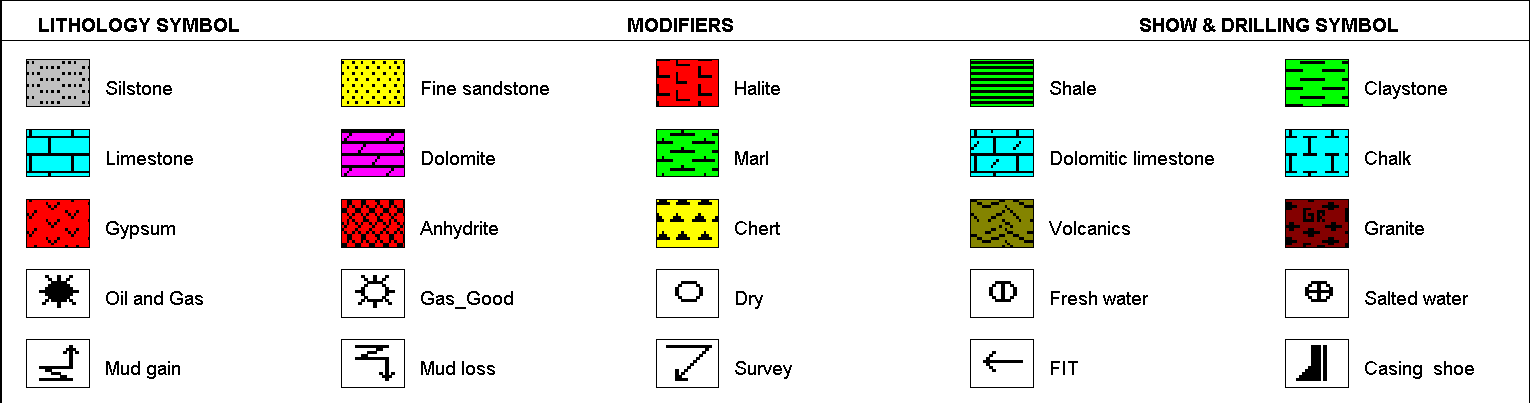

In [92]:
crop_rgb(Image.open(data_df.loc[0]["Image"]), data_df.loc[0]["Lithology Legend"])